# Entrenamiento del detector de emociones

Vamos a entrenar una red que reconozca la emoción de una cara, para usarla luego en el juego de Simón dice.

- **Dataset:** AffectNet de Kaggle (https://www.kaggle.com/datasets/fatihkgg/affectnet-yolo-format). Son fotos de caras a color de 96x96 con 8 emociones. Lo pasamos a carpetas con `preparar_affectnet.py` (una carpeta por emoción).
  - train: 17101 fotos (para entrenar)
  - valid: 5406 fotos (para ver cómo va en cada época)
  - test: 2755 fotos (para la nota final)
- **Modelo:** ResNet18 ya entrenada con ImageNet. Solo le cambiamos la última capa para que tenga 8 salidas (una por emoción) y la volvemos a entrenar con nuestras fotos (esto se llama fine-tuning).

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# usamos la gráfica si hay, si no el procesador
if torch.cuda.is_available():
    dispositivo = "cuda"
else:
    dispositivo = "cpu"
print("Usando:", dispositivo)

Usando: cuda


## 1. Cargar las fotos

A cada foto le hacemos esto antes de dársela a la red:
- `Resize((224, 224))`: la ponemos a 224x224, que es el tamaño con el que se entrenó la ResNet.
- `ToTensor()`: la pasamos a tensor (los números que usa PyTorch) y los valores pasan de 0-255 a 0-1.
- `Normalize(...)`: restamos la media y dividimos por la desviación de ImageNet, porque la ResNet aprendió con las fotos así.

`ImageFolder` lee la carpeta y cada subcarpeta es una clase. `DataLoader` va dando las fotos de 64 en 64 (lotes). En train las barajamos (`shuffle=True`).

In [3]:
transformacion = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

datos_train = datasets.ImageFolder("datasets/affectnet/train", transform=transformacion)
datos_valid = datasets.ImageFolder("datasets/affectnet/valid", transform=transformacion)
datos_test = datasets.ImageFolder("datasets/affectnet/test", transform=transformacion)

train = DataLoader(datos_train, batch_size=64, shuffle=True)
valid = DataLoader(datos_valid, batch_size=64)
test = DataLoader(datos_test, batch_size=64)

emociones = datos_train.classes
print("Emociones:", emociones)
print("Fotos train:", len(datos_train), " valid:", len(datos_valid), " test:", len(datos_test))

Emociones: ['Anger', 'Contempt', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
Fotos train: 17101  valid: 5406  test: 2755


Miramos cuántas fotos hay de cada emoción. Están bastante igualadas, así que el modelo no debería tener favoritas.

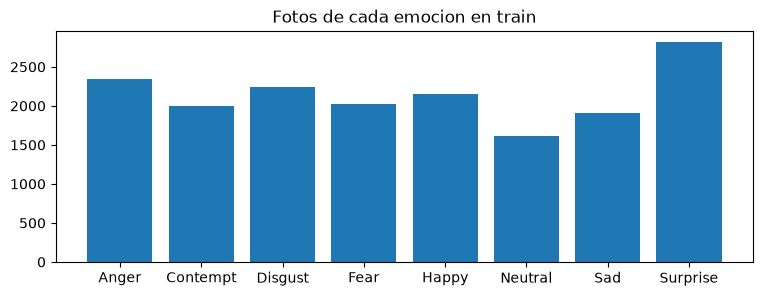

In [4]:
cantidades = []
for i in range(len(emociones)):
    cantidades.append(datos_train.targets.count(i))

plt.figure(figsize=(9, 3))
plt.bar(emociones, cantidades)
plt.title("Fotos de cada emocion en train")
plt.show()

## 2. Crear el modelo

Cogemos la ResNet18 con los pesos de ImageNet y cambiamos la última capa (`fc`): tenía 1000 salidas (las clases de ImageNet) y la ponemos con 8, una por emoción.

In [5]:
modelo = models.resnet18(weights="DEFAULT")
modelo.fc = nn.Linear(512, len(emociones))   # 512 = lo que sale de la capa anterior
modelo = modelo.to(dispositivo)

## 3. Entrenar

- `CrossEntropyLoss`: la pérdida, mide cuánto se equivoca el modelo.
- `Adam` con `lr=0.0001`: el optimizador que va cambiando los pesos. El lr es pequeño porque la red ya viene entrenada y solo queremos ajustarla.

En cada lote: predecimos, calculamos la pérdida, `backward()` calcula cómo cambiar los pesos y `step()` los cambia.

Al final de cada época miramos el acierto en train y en valid. Si es el mejor resultado en valid hasta ahora, guardamos el modelo (así si luego empeora nos quedamos con el bueno).

In [6]:
import time

EPOCAS = 10
perdida_fn = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.0001)

# aquí vamos guardando los resultados para las gráficas
perdidas_train = []
perdidas_valid = []
aciertos_train = []
aciertos_valid = []
mejor = 0
inicio = time.time()   # para saber cuánto tarda el entreno

for epoca in range(EPOCAS):

    # entrenamiento
    modelo.train()
    perdida_total = 0
    bien = 0
    for fotos, etiquetas in train:
        fotos = fotos.to(dispositivo)
        etiquetas = etiquetas.to(dispositivo)

        salida = modelo(fotos)                  
        perdida = perdida_fn(salida, etiquetas)  

        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()

        perdida_total = perdida_total + perdida.item() * len(etiquetas)
        bien = bien + (salida.argmax(1) == etiquetas).sum().item()

    perdidas_train.append(perdida_total / len(datos_train))
    aciertos_train.append(bien / len(datos_train))

    # validación
    modelo.eval()
    perdida_total = 0
    bien = 0
    with torch.no_grad():
        for fotos, etiquetas in valid:
            fotos = fotos.to(dispositivo)
            etiquetas = etiquetas.to(dispositivo)
            salida = modelo(fotos)
            perdida_total = perdida_total + perdida_fn(salida, etiquetas).item() * len(etiquetas)
            bien = bien + (salida.argmax(1) == etiquetas).sum().item()

    perdidas_valid.append(perdida_total / len(datos_valid))
    aciertos_valid.append(bien / len(datos_valid))

    print("Epoca", epoca + 1, "- acierto train:", round(aciertos_train[-1], 3), " acierto valid:", round(aciertos_valid[-1], 3))

    # guardamos el modelo si es el mejor hasta ahora
    if aciertos_valid[-1] > mejor:
        mejor = aciertos_valid[-1]
        torch.save(modelo.state_dict(), "modelo_emociones.pt")
        print("   guardado (es el mejor hasta ahora)")

minutos = (time.time() - inicio) / 60
print("Tiempo de entrenamiento:", round(minutos, 1), "minutos")


Epoca 1 - acierto train: 0.554  acierto valid: 0.659
   guardado (es el mejor hasta ahora)
Epoca 2 - acierto train: 0.771  acierto valid: 0.677
   guardado (es el mejor hasta ahora)
Epoca 3 - acierto train: 0.915  acierto valid: 0.687
   guardado (es el mejor hasta ahora)
Epoca 4 - acierto train: 0.982  acierto valid: 0.684
Epoca 5 - acierto train: 0.995  acierto valid: 0.691
   guardado (es el mejor hasta ahora)
Epoca 6 - acierto train: 0.998  acierto valid: 0.691
Epoca 7 - acierto train: 0.998  acierto valid: 0.693
   guardado (es el mejor hasta ahora)
Epoca 8 - acierto train: 0.998  acierto valid: 0.684
Epoca 9 - acierto train: 0.953  acierto valid: 0.641
Epoca 10 - acierto train: 0.966  acierto valid: 0.671
Tiempo de entrenamiento: 15.5 minutos


## 4. Gráficas

La pérdida tiene que bajar y el acierto subir. Si en train sigue mejorando pero en valid no, el modelo se está aprendiendo las fotos de memoria (overfitting).

La línea discontinua marca la mejor época en valid, que es el modelo que nos quedamos. Debajo ponemos en qué ordenador se ha entrenado, para poder comparar tiempos (por ejemplo mi portátil y el PC de mi compañero).

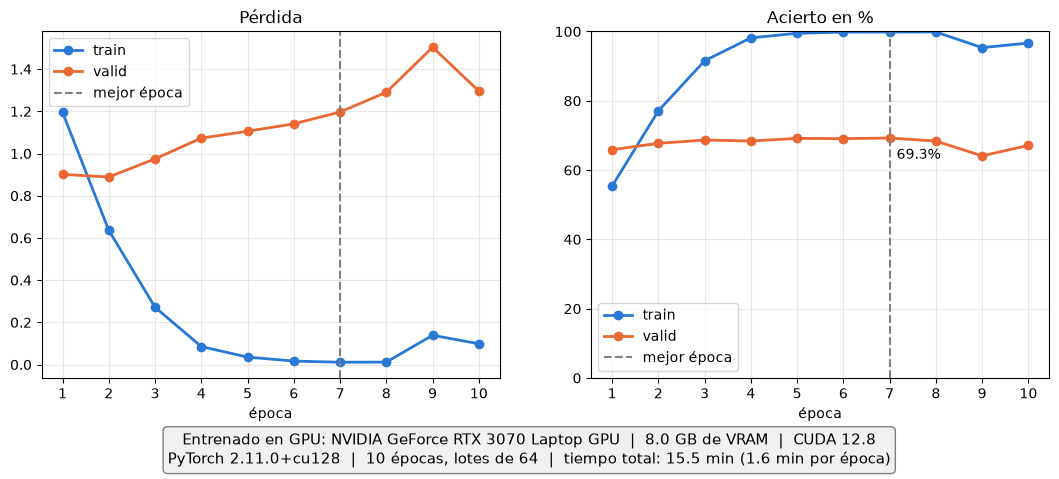

In [10]:
import platform

epocas = range(1, EPOCAS + 1)
mejor_epoca = aciertos_valid.index(max(aciertos_valid)) + 1   # +1 porque las épocas empiezan en 1

# pasamos el acierto a porcentaje para que se lea mejor
acierto_train_100 = []
acierto_valid_100 = []
for i in range(EPOCAS):
    acierto_train_100.append(aciertos_train[i] * 100)
    acierto_valid_100.append(aciertos_valid[i] * 100)

plt.figure(figsize=(13, 4.5))

plt.subplot(1, 2, 1)
plt.plot(epocas, perdidas_train, "o-", color="#2a78d6", linewidth=2, label="train")
plt.plot(epocas, perdidas_valid, "o-", color="#eb6834", linewidth=2, label="valid")
plt.axvline(mejor_epoca, color="gray", linestyle="--", label="mejor época")
plt.title("Pérdida")
plt.xlabel("época")
plt.xticks(epocas)
plt.grid(alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epocas, acierto_train_100, "o-", color="#2a78d6", linewidth=2, label="train")
plt.plot(epocas, acierto_valid_100, "o-", color="#eb6834", linewidth=2, label="valid")
plt.axvline(mejor_epoca, color="gray", linestyle="--", label="mejor época")
plt.text(mejor_epoca + 0.15, max(acierto_valid_100) - 6, str(round(max(acierto_valid_100), 1)) + "%")
plt.title("Acierto en %")
plt.xlabel("época")
plt.xticks(epocas)
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()

if dispositivo == "cuda":
    tarjeta = torch.cuda.get_device_properties(0)
    texto = "Entrenado en GPU: " + tarjeta.name + "  |  " + str(round(tarjeta.total_memory / 1024**3, 1)) + " GB de VRAM"
    texto = texto + "  |  CUDA " + torch.version.cuda
else:
    texto = "Entrenado en CPU: " + platform.processor()
texto = texto + "\nPyTorch " + torch.__version__ + "  |  " + str(EPOCAS) + " épocas, lotes de 64"
texto = texto + "  |  tiempo total: " + str(round(minutos, 1)) + " min (" + str(round(minutos / EPOCAS, 1)) + " min por época)"

plt.figtext(0.5, -0.08, texto, ha="center", fontsize=11,
            bbox=dict(boxstyle="round", facecolor="#f0f0f0", edgecolor="gray"))

plt.show()


## 5. Resultado final con test

Cargamos el mejor modelo que se guardó y lo probamos con las fotos de test, que no ha visto nunca.
- `classification_report`: precisión, recall y f1 de cada emoción (como en los cuadernos del profe).
- Matriz de confusión: en la diagonal están los aciertos, y fuera se ve con qué emoción confunde cada una.

              precision    recall  f1-score   support

       Anger       0.74      0.64      0.69       383
    Contempt       0.67      0.71      0.69       332
     Disgust       0.61      0.68      0.64       327
        Fear       0.75      0.68      0.71       318
       Happy       0.83      0.86      0.84       399
     Neutral       0.52      0.61      0.56       250
         Sad       0.63      0.58      0.61       278
    Surprise       0.72      0.70      0.71       468

    accuracy                           0.69      2755
   macro avg       0.68      0.68      0.68      2755
weighted avg       0.70      0.69      0.69      2755



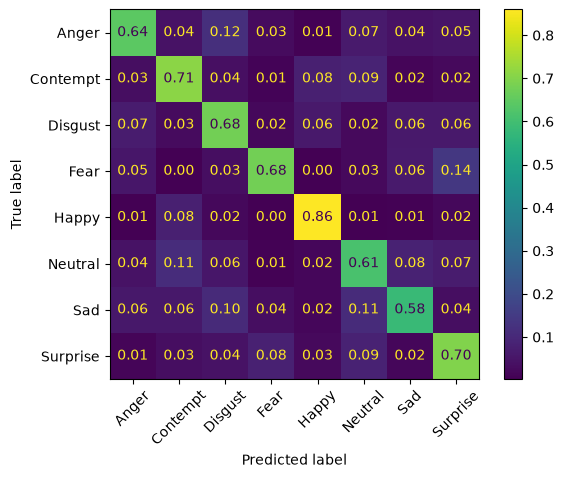

In [8]:
modelo.load_state_dict(torch.load("modelo_emociones.pt"))
modelo.eval()

reales = []
predichas = []
with torch.no_grad():
    for fotos, etiquetas in test:
        salida = modelo(fotos.to(dispositivo))
        predichas = predichas + salida.argmax(1).cpu().tolist()
        reales = reales + etiquetas.tolist()

print(classification_report(reales, predichas, target_names=emociones))

ConfusionMatrixDisplay.from_predictions(reales, predichas, display_labels=emociones,
                                        normalize="true", values_format=".2f", xticks_rotation=45)
plt.show()

## 6. Extra: comparar con DeepFace

DeepFace también detecta emociones (pero no tiene Contempt, así que esas fotos las saltamos). Probamos los dos con 300 fotos de test y miramos cuál acierta más y cuál es más rápido.

In [9]:
import time
import random
from PIL import Image
from deepface import DeepFace

# los nombres de deepface son distintos a los nuestros
nombres_deepface = {"angry": "Anger", "disgust": "Disgust", "fear": "Fear", "happy": "Happy",
                    "neutral": "Neutral", "sad": "Sad", "surprise": "Surprise"}

random.seed(0)
fotos_prueba = random.sample(datos_test.samples, 400)

bien_nuestro = 0
bien_deepface = 0
tiempo_nuestro = 0
tiempo_deepface = 0
n = 0

for ruta, etiqueta in fotos_prueba:
    real = emociones[etiqueta]
    if real == "Contempt":
        continue
    if n == 300:
        break
    n = n + 1

    # nuestro modelo
    inicio = time.time()
    foto = transformacion(Image.open(ruta)).unsqueeze(0).to(dispositivo)
    with torch.no_grad():
        prediccion = emociones[modelo(foto).argmax(1).item()]
    tiempo_nuestro = tiempo_nuestro + time.time() - inicio
    if prediccion == real:
        bien_nuestro = bien_nuestro + 1

    # deepface
    inicio = time.time()
    resultado = DeepFace.analyze(ruta, actions=["emotion"], detector_backend="skip", silent=True)
    tiempo_deepface = tiempo_deepface + time.time() - inicio
    if nombres_deepface[resultado[0]["dominant_emotion"]] == real:
        bien_deepface = bien_deepface + 1

print("Nuestro modelo: acierto", round(bien_nuestro / n, 3), " tiempo por foto:", round(tiempo_nuestro / n * 1000, 1), "ms")
print("DeepFace:       acierto", round(bien_deepface / n, 3), " tiempo por foto:", round(tiempo_deepface / n * 1000, 1), "ms")


Nuestro modelo: acierto 0.683  tiempo por foto: 14.8 ms
DeepFace:       acierto 0.343  tiempo por foto: 23.4 ms
